In [1]:
using FFTW, Plots, DataFrames
using Test
gr(framestyle=:box)

Plots.GRBackend()

In [2]:
"""
ypred, info = Fourier(y, P)

## Arguments
- P: period of the signal

## 要求
- 均匀步长
- 不能存在缺失值NaN
"""
function Fourier(y::AbstractVector{FT}, P::FT=length(y); threshold=0.95) where {FT<:Real}
  N = length(y)
  Δt = P / N
  t = 0.0:Δt:(P-Δt)   # lenght(t) == N

  # freq = 1 ./ t
  freq = fftfreq(N, 1 / Δt)
  ## 快速傅里叶变化
  len = N ÷ 2
  Fy = fft(y)[1:len]
  ak = 2 / N * real.(Fy)
  bk = -2 / N * imag.(Fy)  # fft sign convention
  ak[1] = ak[1] / 2

  ## 识别功率谱
  power = abs.(Fy) .^ 2
  inds = sortperm(power, rev=true)
  explain = power[inds] / sum(power)
  accu_explain = cumsum(explain)

  ## 挑选谐波数
  m = findfirst(accu_explain .>= threshold)  # 95% explained
  info = DataFrame(; k=1:len, freq=freq[1:len][inds], explain, accu_explain)[1:m, :] # index=inds

  ## 重建信号
  yr = zeros(N, 1)
  for i in 1:m
    k = inds[i]
    yr .+= ak[k] * cos.(2π * (k - 1) / P * t) .+ bk[k] * sin.(2π * (k - 1) / P * t)
  end
  (; ypred = yr, info)
end

Fourier

In [14]:
function test_fourier(func; is_plot=true)
  N = 2^12 - 1
  P = 10.0 #
  Δt = P / N
  t = 0.0:Δt:(P-Δt)   # lenght(t) == N
  y = func.(t)
  ypred, info = Fourier(y, P)

  linewidth = 1
  if is_plot
    p = plot(t, y; legend=true, linewidth, xlim=(0, 0.1), label="Origin")
    plot!(p, t, ypred; linestyle=:dash, linewidth, label="Fourier")
    display(p)
  end
  return info
end

# y = sin(Ax + b)
# T = 2π / A
# f = 1 / T = A / 2π

test_fourier (generic function with 1 method)

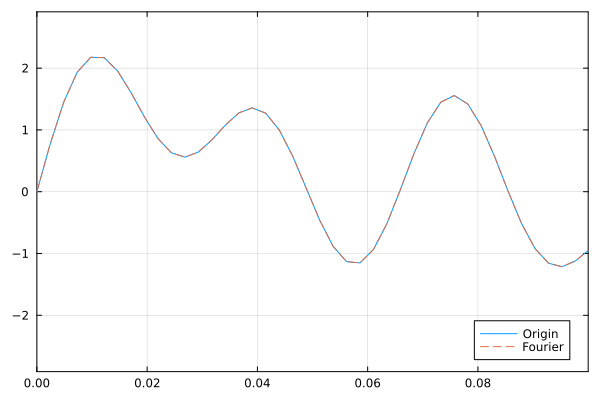

Row,k,freq,explain,accu_explain
,Int64,Float64,Float64,Float64
1,1,15.0,0.333333,0.333333
2,2,30.0,0.333333,0.666667
3,3,7.0,0.333333,1.0


In [15]:
# 三个高频信号：7Hz, 15Hz, 30Hz
func1(t) = sin(2π * 7 * t) + sin(2π * 15 * t) + sin(2π * 30 * t)

info = test_fourier(func1)
@test sort(info.freq) == [7.0, 15., 30.]  # 60Hz, 120Hz
info

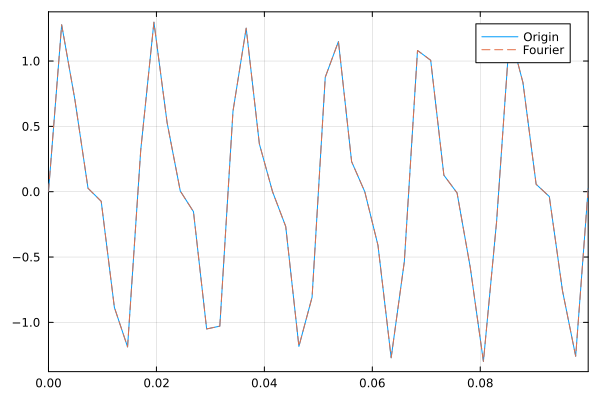

Row,k,freq,explain,accu_explain
,Int64,Float64,Float64,Float64
1,1,60.0,0.8,0.8
2,2,120.0,0.2,1.0


In [16]:
# 两个高频信号：60Hz, 120Hz
func2(t) = sin(2π * 60 * t) + 0.5 * sin(2π * 120 * t)

info = test_fourier(func2)
@test info.freq == [60.0, 120.0]  # 60Hz, 120Hz
info